# Lab 1 — Telco Customer Churn

**Student:** RUKUNDO Elie
**Dataset:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)

## Introduction

The goal of this lab is to explore the "Telco Customer Churn" dataset and
understand which factors are associated with whether a telecom customer
cancels (churns) their service.

The work is organized as follows:

1. **Loading** the raw CSV into a pandas DataFrame.
2. **Inspecting** its structure — head, tail, dtypes — to understand the shape and quality of the data.
3. **Preprocessing** — encoding the target `Churn` as 0/1, correcting the datatype of `TotalCharges`, and removing rows with missing values.
4. **Exploration** — analyzing how churn relates to:
   - demographics (gender, senior citizen, partner, dependents),
   - services (phone service),
   - and payments (contract, paperless billing, payment method).

The findings from this analysis serve as a first step toward building a predictive churn model in a later lab.

In [12]:
# Imports used throughout the lab
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make plots look nicer
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# Ensure the images folder exists (used later when we save plots)
import os
os.makedirs("../images", exist_ok=True)

## Task ii — Load the Dataset

In [25]:
# Load the CSV file
df = pd.read_csv("data/Telco-Customer-Churn.csv")

# Print the shape (rows, columns)
print(f"Dataset shape: {df.shape}")

Dataset shape: (7043, 21)


In [9]:
import os
print(os.getcwd())

C:\Users\user\documents\telco-customer-churn-lab


## Task iii — Display Head and Tail

In [26]:
# Display the first 5 rows
print("=== HEAD ===")
display(df.head())

# Display the last 5 rows
print("\n=== TAIL ===")
display(df.tail())

=== HEAD ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



=== TAIL ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [10]:
print(os.listdir())

['.git', '.gitignore', '.ipynb_checkpoints', 'data', 'images', 'Lab1_Churn_Analysis.ipynb.ipynb', 'notebooks', 'README.md']


## Task iv — Data Preprocessing
**1. Encode Churn:** Convert "Yes" to 1 and "No" to 0 so machine learning models can use it.

In [27]:
# Convert Yes to 1 and No to 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Display the counts to verify
print(df['Churn'].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [18]:
import os

print("I am currently running in this folder:\n", os.getcwd())
print("\nHere are the files/folders I can see right now:")
for item in os.listdir():
    print("-", item)

# Check if the data folder is next to us or one level up
if os.path.exists("data"):
    print("\n✅ Found a 'data' folder right here. Files inside it:", os.listdir("data"))
elif os.path.exists("../data"):
    print("\n✅ Found a 'data' folder one level up. Files inside it:", os.listdir("../data"))
else:
    print("\n❌ Could not find the 'data' folder!")

I am currently running in this folder:
 C:\Users\user\documents\telco-customer-churn-lab

Here are the files/folders I can see right now:
- .git
- .gitignore
- .ipynb_checkpoints
- data
- images
- Lab1_Churn_Analysis.ipynb.ipynb
- notebooks
- README.md

✅ Found a 'data' folder right here. Files inside it: ['Telco-Customer-Churn.csv.csv']


**2. Fix DataTypes:** Check current data types. `TotalCharges` is currently an object (text) because it has blank spaces. We will convert it to a numeric float.

In [28]:
# Display the datatypes BEFORE
print("=== BEFORE ===")
print(df.dtypes)

# Convert TotalCharges to numeric (errors='coerce' turns blanks into NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Display the datatypes AFTER
print("\n=== AFTER ===")
print(df.dtypes)

=== BEFORE ===
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                 int64
dtype: object

=== AFTER ===
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
Stre

In [ ]:
# Convert Yes to 1 and No to 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
print(df['Churn'].value_counts())

**3. Handle Nulls:** Display the columns with null values and remove those rows from the dataset.

In [29]:
# Display null values per column
print("Null values before:")
print(df.isnull().sum())

# Drop the rows with null values
df = df.dropna().reset_index(drop=True)

print("\nRemaining nulls:")
print(df.isnull().sum().sum())
print("\nNew dataset shape:", df.shape)

Null values before:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Remaining nulls:
0

New dataset shape: (7032, 21)


In [ ]:
# Check datatypes before
print("=== BEFORE ===")
print(df.dtypes)

# Convert TotalCharges to numeric (turns blanks into NaN)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("\n=== AFTER ===")
print(df.dtypes)

## Task v — Data Exploration
First, let's define a helper function to quickly plot the churn counts and churn rate for any column.

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

def plot_churn(col):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Plot 1: Count of customers
    sns.countplot(data=df, x=col, hue='Churn', ax=axes[0], palette='Set2')
    axes[0].set_title(f'Count of {col} by Churn')
    
    # Plot 2: Churn Rate (%)
    churn_rate = df.groupby(col)['Churn'].mean().mul(100).reset_index()
    sns.barplot(data=churn_rate, x=col, y='Churn', ax=axes[1], palette='rocket')
    axes[1].set_title(f'Churn Rate (%) by {col}')
    axes[1].set_ylabel('Churn Rate (%)')
    
    # Add the percentage text on top of the bars
    for i in axes[1].containers:
        axes[1].bar_label(i, fmt='%.1f%%')
        
    plt.tight_layout()
    plt.show()

In [ ]:
# Drop the 11 rows with missing TotalCharges
df = df.dropna().reset_index(drop=True)

print("Remaining nulls:", df.isnull().sum().sum())
print("New shape:", df.shape)

## Task v — Data Exploration
### a. Demographic Analysis
First, we will define a helper function that automatically plots the count of customers and the churn rate (%) for any given column.

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style
sns.set_style("whitegrid")

def plot_churn(col):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    # Plot 1: Count of customers
    sns.countplot(data=df, x=col, hue='Churn', ax=axes[0], palette='Set2')
    axes[0].set_title(f'Count of {col} by Churn')
    
    # Plot 2: Churn Rate (%)
    churn_rate = df.groupby(col)['Churn'].mean().mul(100).reset_index()
    sns.barplot(data=churn_rate, x=col, y='Churn', ax=axes[1], palette='rocket')
    axes[1].set_title(f'Churn Rate (%) by {col}')
    axes[1].set_ylabel('Churn Rate (%)')
    
    # Add the percentage text on top of the bars
    for i in axes[1].containers:
        axes[1].bar_label(i, fmt='%.1f%%')
        
    plt.tight_layout()
    plt.show()

#### 1. Gender Distribution against Churn

C:\Users\user\AppData\Local\Temp\ipykernel_24068\3985157321.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_rate, x=col, y='Churn', ax=axes[1], palette='rocket')


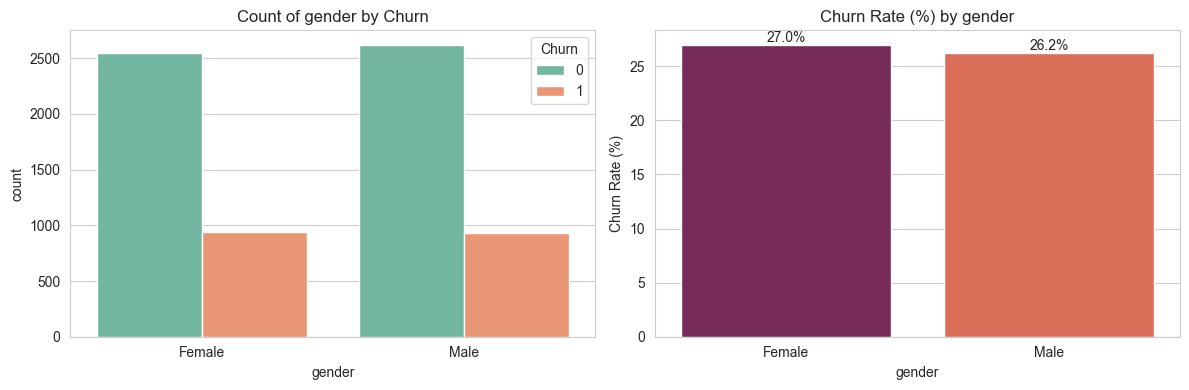

In [32]:
plot_churn('gender')

**Interpretation:** 
Gender does not seem to be a strong factor in churn. Both male and female customers churn at roughly the same rate (~26-27%). We can consider gender as a low-priority feature for predicting churn.

#### 2. Senior Citizen against Churn

C:\Users\user\AppData\Local\Temp\ipykernel_24068\3985157321.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_rate, x=col, y='Churn', ax=axes[1], palette='rocket')


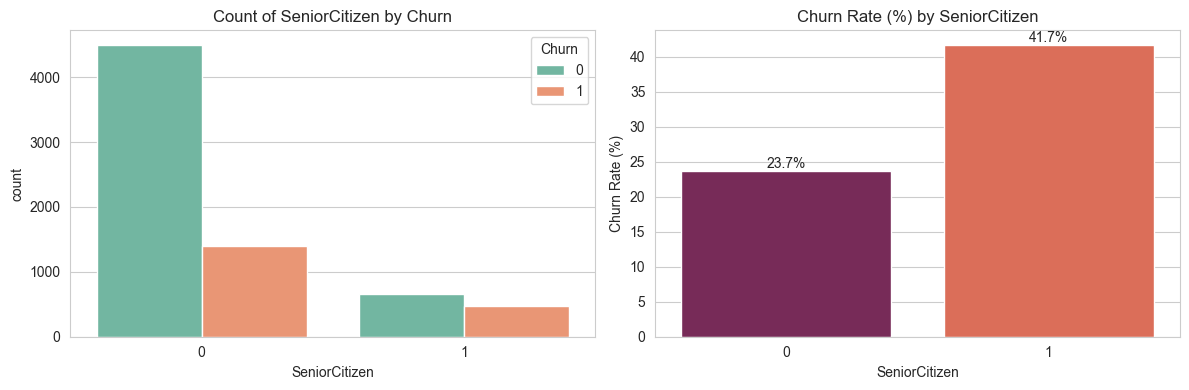

In [33]:
plot_churn('SeniorCitizen')

**Interpretation:** 
Senior citizens churn at a significantly higher rate (~41%) compared to non-seniors (~24%). This is a key demographic to target for retention campaigns.

#### 3. Partner against Churn

C:\Users\user\AppData\Local\Temp\ipykernel_24068\3985157321.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=churn_rate, x=col, y='Churn', ax=axes[1], palette='rocket')


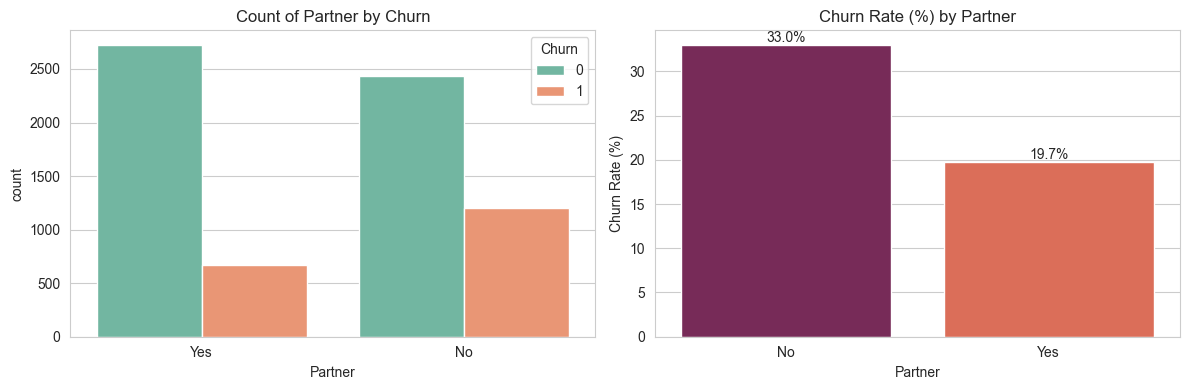

In [34]:
plot_churn('Partner')